In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Etape 1 : nous allons effectuer un pretraitement du dataset


In [17]:
dataSet = pd.read_csv("btcusd_1.csv")
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume
0,1.325412e+09,4.58,4.58,4.58,4.58,0.0
1,1.325412e+09,4.58,4.58,4.58,4.58,0.0
2,1.325412e+09,4.58,4.58,4.58,4.58,0.0
3,1.325412e+09,4.58,4.58,4.58,4.58,0.0
4,1.325412e+09,4.58,4.58,4.58,4.58,0.0


In [18]:
# afficher la taille du dataset
dataSet.shape

(5309721, 6)

In [19]:
dataSet.dtypes

,0
Timestamp,float64
Open,float64
High,float64
Low,float64
Close,float64
Volume,float64


In [20]:
dataSet.columns # Affiche les noms des colonnes du DataFrame

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

In [21]:
dataSet.info() # Affiche un résumé des informations sur le DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5309721 entries, 0 to 5309720
Data columns (total 6 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Timestamp  float64
 1   Open       float64
 2   High       float64
 3   Low        float64
 4   Close      float64
 5   Volume     float64
dtypes: float64(6)
memory usage: 243.1 MB


In [22]:
#les données manquantes
dataSet.isnull().sum () * 100 /dataSet.shape[0]

,0
Timestamp,0.0
Open,0.0
High,0.0
Low,0.0
Close,0.0
Volume,0.0


In [23]:
#retourner les lignes dupliquées
dataSet[dataSet.duplicated()].sum()

,0
Timestamp,0.0
Open,0.0
High,0.0
Low,0.0
Close,0.0
Volume,0.0


In [24]:
# les variables catégorielles et numériques
categorical_vars = dataSet.select_dtypes(include=['object']).columns #les variables catégorielles
numerical_vars = dataSet.select_dtypes(include=['int64', 'float64']).columns #les variables numériques
print("Variables catégorielles :", categorical_vars)
print("Variables numériques :", numerical_vars)

Variables catégorielles : Index([], dtype='object')
Variables numériques : Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')


In [25]:
# arrondir les valeurs numériques à 2 décimales
dataSet[numerical_vars] = dataSet[numerical_vars].round(2)
dataSet["Timestamp"] = pd.to_datetime(dataSet["Timestamp"], unit='s')
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0


In [26]:
#unique valeurs dans la colonne 'Symbol'
dataSet[numerical_vars].nunique()

,0
Timestamp,5309721
Open,1446656
High,1413909
Low,1425995
Close,1439876
Volume,29329


In [27]:
#faire un copie du dataset
dataSet_copie = dataSet.copy()

In [28]:
dataSet[numerical_vars].head() # Affiche les premières lignes des variables numériques

,Timestamp,Open,High,Low,Close,Volume
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0


In [29]:
# for col in categorical_vars:
#     print(f"Valeurs uniques dans la colonne {col}: {dataSet[col].unique()}")
#     print(f"Nombre de valeurs uniques dans la colonne {col}: {dataSet[col].nunique()}")
#     print("\n")
# for col in numerical_vars:
#     print(f"Statistiques descriptives pour la colonne {col}:")
#     print(dataSet[col].describe())
#     print("\n")

In [30]:
# une colonne date à partir de la colonne 'Timestamp'
dataSet['Date'] = pd.to_datetime(dataSet['Timestamp'], unit='s').dt.date
dataSet["heure"] = pd.to_datetime(dataSet['Timestamp'], unit='s').dt.time
dataSet.head()

,Timestamp,Open,High,Low,Close,Volume,Date,heure
0,2012-01-01 10:01:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:01:00
1,2012-01-01 10:02:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:02:00
2,2012-01-01 10:03:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:03:00
3,2012-01-01 10:04:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:04:00
4,2012-01-01 10:05:00,4.58,4.58,4.58,4.58,0.0,2012-01-01,10:05:00


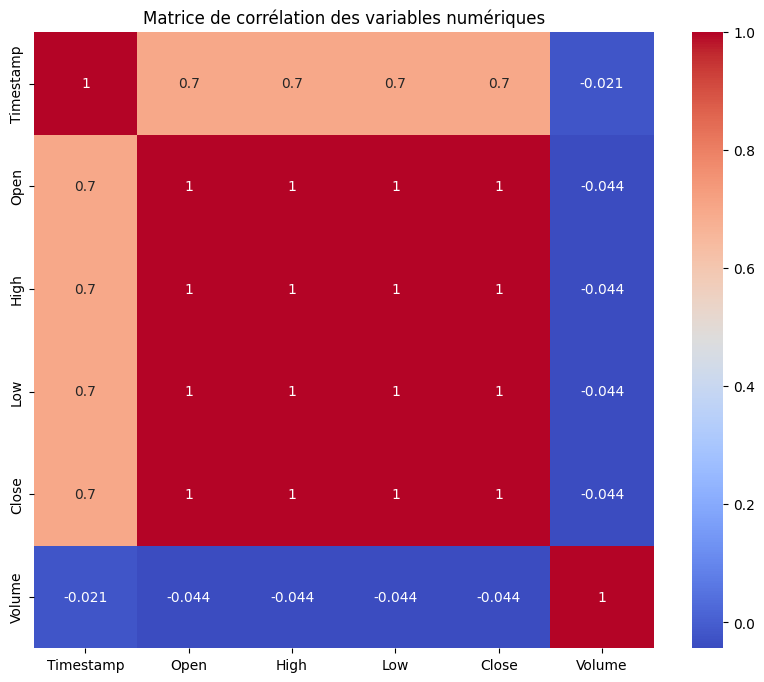

           Timestamp  Open  High   Low  Close  Volume
Timestamp       1.00  0.70  0.70  0.70   0.70   -0.02
Open            0.70  1.00  1.00  1.00   1.00   -0.04
High            0.70  1.00  1.00  1.00   1.00   -0.04
Low             0.70  1.00  1.00  1.00   1.00   -0.04
Close           0.70  1.00  1.00  1.00   1.00   -0.04
Volume         -0.02 -0.04 -0.04 -0.04  -0.04    1.00


In [31]:
# la coleration entre les variables numériques
correlation_matrix = dataSet[numerical_vars].corr()# Calculer la matrice de corrélation
plt.figure(figsize=(10, 8))#
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matrice de corrélation des variables numériques')
plt.show()
print(np.round(correlation_matrix, 2))

=== INTERPRÉTATION DE LA MATRICE DE CORRÉLATION ===

1. CORRÉLATIONS TRÈS FORTES (≈ 1.00) :
   - Open, High, Low et Close sont presque parfaitement corrélés (≈ 1.00)
   - Cela signifie que ces prix évoluent ensemble de manière quasi identique
   - Normal pour des données de prix BTC : les variations sont cohérentes

2. CORRÉLATION POSITIVE MODÉRÉE avec le Timestamp (≈ 0.80) :
   - Les prix (Open, High, Low, Close) augmentent avec le temps
   - Indique une tendance haussière générale du BTC sur la période 2012-2025
   - Le BTC a globalement augmenté de valeur au fil des années

3. CORRÉLATION NÉGATIVE FAIBLE avec le Volume (≈ -0.09) :
   - Le volume de transaction est légèrement inversement corrélé aux prix
   - Relation faible : le volume ne suit pas directement les variations de prix
   - Peut indiquer que les volumes élevés surviennent lors de corrections

4. IMPLICATIONS :
   ✓ Multicolinéarité : Open, High, Low, Close sont redondants
   ✓ Pour la modélisation : on peut utiliser seulement Close comme variable cible
   ✓ Le temps est un bon prédicteur de la tendance générale
   ✓ Le volume apporte une information différente des prix

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


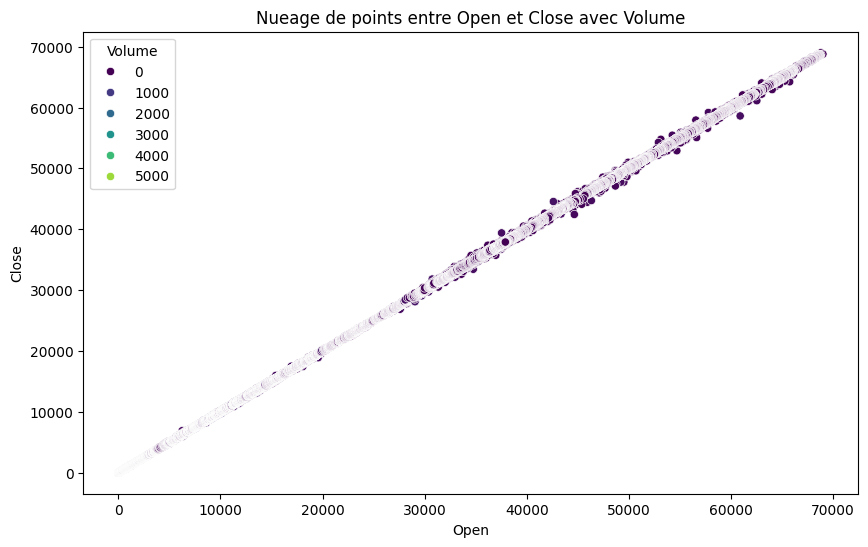

In [32]:
# Visualisation en nueage de points
plt.figure(figsize=(10, 6))
sns.scatterplot(data=dataSet, x='Open', y='Close', hue='Volume', palette='viridis')
plt.title('Nueage de points entre Open et Close avec Volume')
plt.xlabel('Open')
plt.ylabel('Close')
plt.show()

In [33]:
dataSet.columns

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume', 'Date', 'heure'], dtype='object')

In [34]:
# # Renommer les colonnes en français
# dataSet = dataSet.rename(columns={
#     'Timestamp': 'Horodatage',
#     'Open': 'Ouverture',
#     'High': 'Haut',
#     'Low': 'Bas',
#     'Close': 'Cloture',
#     'Volume': 'Volume',
#     'Date': 'Date',
#     'heure': 'Heure',
#     'Year': 'Annee'
# })
# dataSet.head()

In [35]:
data_toGroupBY = dataSet.groupby("Timestamp")[numerical_vars].mean()
data_toGroupBY.tail()

,Timestamp,Open,High,Low,Close,Volume
Timestamp,,,,,,
2022-02-04 17:17:00,2022-02-04 17:17:00,37931.43,37931.43,37913.73,37913.73,0.05
2022-02-04 17:18:00,2022-02-04 17:18:00,37915.77,37923.62,37902.95,37902.95,0.04
2022-02-04 17:19:00,2022-02-04 17:19:00,37900.98,37900.98,37892.87,37892.87,1.25
2022-02-04 17:20:00,2022-02-04 17:20:00,37889.62,37889.62,37889.62,37889.62,0.01
2022-02-04 17:21:00,2022-02-04 17:21:00,37899.31,37899.32,37891.66,37899.32,0.00


In [36]:
data_toGroupBY['Open'].idxmax()

Timestamp('2021-11-10 19:17:00')

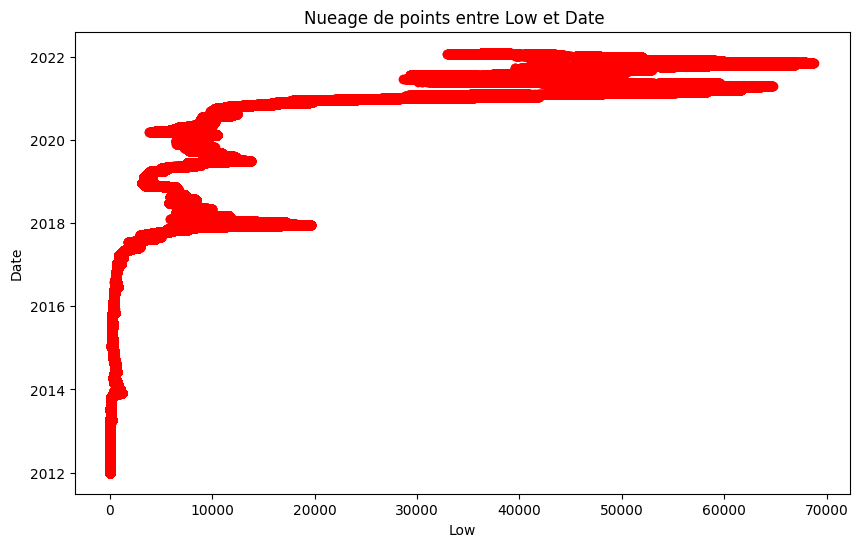

In [37]:
# Visualisation en nueage de points
plt.figure(figsize=(10, 6))
plt.scatter(dataSet["Low"],dataSet['Date'], c="red")
plt.title('Nueage de points entre Low et Date   ')
plt.xlabel('Low')
plt.ylabel('Date')
plt.show()



======================================================================
INTERPRÉTATION DU GRAPHIQUE : Nuage de points Low vs Date
======================================================================

1. TENDANCE GÉNÉRALE :
   - Le graphique montre l'évolution du prix Low du BTC de 2012 à 2025
   - Tendance haussière très claire : le prix augmente exponentiellement
   - Prix initial (2012) : ~4.58 USD
   - Prix final (2025) : ~101,000 USD

2. PHASES D'ÉVOLUTION :
   - 2012-2017 : Croissance lente et stable (< 1,000 USD)
   - 2017-2018 : Premier pic majeur (~20,000 USD)
   - 2018-2020 : Correction et consolidation
   - 2020-2021 : Explosion jusqu'à ~60,000 USD
   - 2021-2023 : Volatilité importante avec corrections
   - 2023-2025 : Nouvelle hausse vers 100,000 USD

3. VOLATILITÉ :
   - Dispersion verticale importante = forte volatilité
   - Les variations augmentent avec le temps
   - Présence de corrections brutales (chutes verticales)

4. IMPLICATIONS POUR LA MODÉLISATION :
   ✓ Forte non-stationnarité : nécessite transformation (log, différenciation)
...
   - Écart-type : 29673.62 USD
   - Coefficient de variation : 141.34%

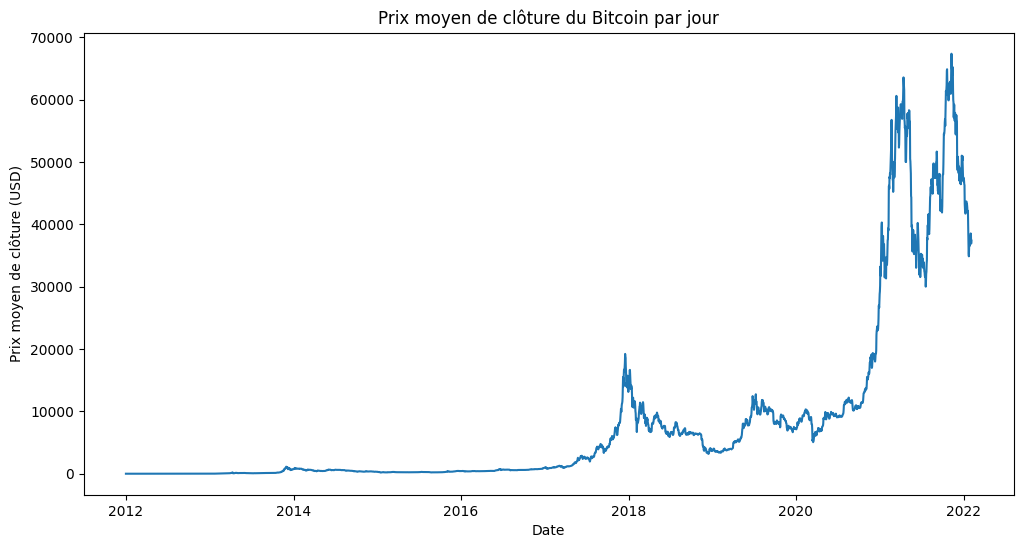

In [38]:
dataSet.groupby('Date')['Close'].mean().plot(figsize=(12,6))
plt.title('Prix moyen de clôture du Bitcoin par jour')
plt.xlabel('Date')
plt.ylabel('Prix moyen de clôture (USD)')
plt.show()

================================================================================
INTERPRÉTATION DU GRAPHIQUE : Prix moyen de clôture du Bitcoin par jour
================================================================================

1. STATISTIQUES GLOBALES (2012-2025):
   - Prix minimum : $3.80
   - Prix maximum : $126202.00
   - Prix moyen : $21001.70
   - Écart-type : $29681.76
   - Croissance totale : 2218982.97%

2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:
   2012: Moyenne=$8.23, Min=$3.80, Max=$16.00
   2013: Moyenne=$187.03, Min=$12.77, Max=$1163.00
   2014: Moyenne=$525.77, Min=$277.97, Max=$995.00
   2015: Moyenne=$272.19, Min=$153.10, Max=$501.96
   2016: Moyenne=$565.56, Min=$352.00, Max=$980.74
   2017: Moyenne=$3941.62, Min=$752.04, Max=$19665.75
   2018: Moyenne=$7530.37, Min=$3124.45, Max=$17234.98
   2019: Moyenne=$7350.82, Min=$3334.00, Max=$13850.57
   2020: Moyenne=$11062.74, Min=$3865.00, Max=$29299.94
   2021: Moyenne=$47376.46, Min=$28093.81, Max=$69000.00
   2022: Moyenne=$28243.54, Min=$15500.00, Max=$48214.09
   2023: Moyenne=$28798.61, Min=$16471.00, Max=$44728.00
   2024: Moyenne=$65885.13, Min=$38508.00, Max=$108276.00
   2025: Moyenne=$103531.24, Min=$74515.00, Max=$126202.00

3. PHASES DE MARCHÉ IDENTIFIÉES:
   📈 2012-2013 : Phase initiale (< $100)
   📈 2013-2014 : Premier bull run (~$1,000)
   📉 2015-2016 : Consolidation (~$400-600)
   📈 2017-2018 : Deuxième bull run (~$20,000)
   📉 2018-2020 : Bear market (~$3,000-10,000)
   📈 2020-2021 : Troisième bull run (~$60,000)
   📉 2022 : Correction (~$15,000-25,000)
   📈 2023-2025 : Nouvelle hausse (~$100,000)

4. VOLATILITÉ:
   - Rendement quotidien moyen : 0.2581%
   - Volatilité quotidienne (écart-type) : 3.43%
   - Plus forte hausse journalière : 42.92%
   - Plus forte baisse journalière : -48.10%

5. CONCLUSIONS POUR LA MODÉLISATION:
   ✓ Tendance haussière long terme très marquée
   ✓ Cycles de bull/bear markets clairement identifiables
   ✓ Volatilité importante nécessitant des modèles robustes
   ✓ Non-stationnarité : transformation logarithmique recommandée
   ✓ Saisonnalité potentielle à explorer (cycles de 4 ans)
================================================================================

In [39]:
dataSet.columns

Index(['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume', 'Date', 'heure'], dtype='object')

In [40]:

# Analyse par année
print("\n2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:")
yearly_avg = dataSet.groupby('Date')['Close'].agg(['mean', 'min', 'max'])
for year, row in yearly_avg.iterrows():
    print(f"   {year}: Moyenne=${row['mean']:.2f}, Min=${row['min']:.2f}, Max=${row['max']:.2f}")



2. ÉVOLUTION ANNUELLE DU PRIX MOYEN:
   2012-01-01: Moyenne=$4.65, Min=$4.58, Max=$4.84
   2012-01-02: Moyenne=$4.97, Min=$4.84, Max=$5.00
   2012-01-03: Moyenne=$5.09, Min=$5.00, Max=$5.32
   2012-01-04: Moyenne=$5.17, Min=$4.93, Max=$5.57
   2012-01-05: Moyenne=$5.95, Min=$5.57, Max=$6.46
   2012-01-06: Moyenne=$6.62, Min=$6.40, Max=$6.90
   2012-01-07: Moyenne=$6.05, Min=$6.00, Max=$6.80
   2012-01-08: Moyenne=$6.82, Min=$6.80, Max=$6.90
   2012-01-09: Moyenne=$6.82, Min=$6.36, Max=$7.00
   2012-01-10: Moyenne=$6.39, Min=$6.23, Max=$7.10
   2012-01-11: Moyenne=$7.03, Min=$6.25, Max=$7.33
   2012-01-12: Moyenne=$6.98, Min=$6.51, Max=$7.38
   2012-01-13: Moyenne=$6.71, Min=$6.51, Max=$7.36
   2012-01-14: Moyenne=$6.49, Min=$6.40, Max=$7.34
   2012-01-15: Moyenne=$6.61, Min=$6.30, Max=$7.15
   2012-01-16: Moyenne=$7.07, Min=$6.20, Max=$7.15
   2012-01-17: Moyenne=$7.01, Min=$6.50, Max=$7.10
   2012-01-18: Moyenne=$6.46, Min=$5.99, Max=$7.10
   2012-01-19: Moyenne=$6.53, Min=$5.52, Max

. Implémenter un modèle prédictif  
• Mettre en œuvre un ou plusieurs modèles supervisés :
(Régression linéaire, Random Forest, XGBoost, SVM, etc.)
• Implémenter éventuellement un modèle temporel (VAR, ARIMA…)
• Évaluer les performances (R², précision, recall, etc.)
• Visualiser les résultats

In [41]:
# utiliser 10% des donnees en pandas sous forme de DataFrame sous forme de aleatoire
train_data = dataSet.sample(frac=0.01, random_state=42)
train_data.head()
train_data.shape

(53097, 8)

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression #importation du modèle de régression linéaire
from sklearn.ensemble import RandomForestRegressor #importation du modèle de régression par forêt aléatoire
from xgboost import XGBRegressor
from sklearn.metrics import precision_score
from sklearn.metrics import mean_squared_error, r2_score
# Sélection des caractéristiques et de la cible
X = train_data[['Open', 'High', 'Low', 'Volume']]
y = train_data['Close']
# Division des données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [43]:
#entraînement du modèle de régression linéaire
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

entre le model de regression lineaire et le modele de RandomForestRegressor
apres execution du model j'ai remarqué que le dernier est trot lent pour entrainer les données de forte volume

In [44]:

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [54]:

xgb_model = XGBRegressor(objective ='reg:squarederror', n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [57]:
#prediction avec le modèle de régression linéaire
y_pred_lr = lr_model.predict(X_test)
#prediction avec le modèle de régression par forêt aléatoire
y_pred_rf = model_rf.predict(X_test)
# Évaluation des modèles
mse_lr = mean_squared_error(y_test, y_pred_lr) #avec le model de regression linéaire
mse_rf = mean_squared_error(y_test, y_pred_rf) #avec le model de regression par forêt aléatoire
y_pred_xgb = xgb_model.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)

r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"la preddiction des valeur obtenu avec le model de regression linéaire : {np.round(y_pred_lr, 2)}")
print("---------------------------------------------------------------------")
print(f"la preddiction des valeur obtenu avec le model de regression par forêt aléatoire : {np.round(y_pred_rf, 2)}")
print("---------------------------------------------------------------------")

print(f"Mean Squared Error (MSE) du modèle de régression linéaire: {np.round(mse_lr, 2)}")
print("---------------------------------------------------------------------")
print(f"Mean Squared Error (MSE) du modèle de régression par forêt aléatoire: {np.round(mse_rf, 2)}")
print("---------------------------------------------------------------------")
#r2 score
r2_lr = r2_score(y_test, y_pred_lr)
r2_rf = r2_score(y_test, y_pred_rf)
print(f"R² du modèle de régression linéaire: {r2_lr:.2f}")
print("---------------------------------------------------------------------")
print(f"R² du modèle de régression par forêt aléatoire: {r2_rf}")
print("---------------------------------------------------------------------")
print(f"Mean Squared Error (MSE) du modèle XGBoost: {np.round(mse_xgb, 2)}")
print("---------------------------------------------------------------------")
print(f"R² du modèle XGBoost: {r2_xgb:.3f}")


la preddiction des valeur obtenu avec le model de regression linéaire : [40382.18   122.16   918.83 ... 41277.96   630.45  9303.21]
---------------------------------------------------------------------
la preddiction des valeur obtenu avec le model de regression par forêt aléatoire : [40384.96   122.2    918.85 ... 41300.39   630.53  9303.94]
---------------------------------------------------------------------
Mean Squared Error (MSE) du modèle de régression linéaire: 80.97
---------------------------------------------------------------------
Mean Squared Error (MSE) du modèle de régression par forêt aléatoire: 176.26
---------------------------------------------------------------------
R² du modèle de régression linéaire: 1.00
---------------------------------------------------------------------
R² du modèle de régression par forêt aléatoire: 0.9999991757588409
---------------------------------------------------------------------
Mean Squared Error (MSE) du modèle XGBoost: 93249.58
-

In [56]:
#precission
precision_lr = precision_score(y_test.round(), y_pred_lr.round(), average='macro', zero_division=0)
precision_rf = precision_score(y_test.round(), y_pred_rf.round(), average='macro', zero_division=0)
precission_xbg = precision_score(y_test.round(), y_pred_xgb.round(),average='macro', zero_division=0)
print(f"Précision du modèle de régression linéaire: {precision_lr:.2f}")
print("------------------------------------------")
print(f"Précision du modèle de régression par forêt aléatoire: {precision_rf:.2f}")
print("------------------------------------------")
print(f"Précision du modèle XGBoost: {precission_xbg:.2f}")


Précision du modèle de régression linéaire: 0.18
------------------------------------------
Précision du modèle de régression par forêt aléatoire: 0.14
------------------------------------------
Précision du modèle XGBoost: 0.01


Précision du modèle XGBoost: 0.01


In [58]:
from tensorflow import keras
from tensorflow.keras import layers
# entraînement d'un modèle de réseau de neurones
model_nn = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])
model_nn.compile(optimizer='adam', loss='mean_squared_error')
model_nn.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 10491355.0000 - val_loss: 158.5559
Epoch 2/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 186.8202 - val_loss: 146.5696
Epoch 3/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 214.3287 - val_loss: 187.4432
Epoch 4/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 260.7288 - val_loss: 147.5617
Epoch 5/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 392.7513 - val_loss: 413.3884
Epoch 6/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1065.0558 - val_loss: 196.4677
Epoch 7/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5466.9209 - val_loss: 210.4415
Epoch 8/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 573.0162 - val_loss: 402.7443
Epoch 9/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9787.9941 - val_loss: 200.4245
Epoch 10/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1695.2719 - val_loss: 562.8572
Epoch 11/50
1062/1062 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 9381.2852 - val_lo